# Practice 6. Data Transformation & EDA
**Pandas GroupBy, joins, reshaping (pivot/melt) + Matplotlib/Seaborn plots**

**Dataset:** ecommerce_clean.csv — 138,116 online orders (2021–2025), 47 columns: order, customer, payment, delivery, review, marketing and financial fields.
**Database:** SQLite (ecommerce.db) accessed through **SQLAlchemy**.

The CSV is one flat table. Customer attributes are identical for every customer_id, so the file is normalised into four related tables:

Numerical fields: quantity, gross/net sales, discount, tax, shipping cost, profit, age, rating, delivery days. Categorical fields: status, channel, segment, country, payment method, shipping method, etc.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, inspect, text

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 160)

CSV_PATH = "ecommerce_clean.csv"      
DB_URL = "sqlite:///ecommerce.db"

###  relational database from the CSV 
The flat file is split into `customers`, `orders`, `reviews` and `returns` and written to SQLite with SQLAlchemy.

In [ ]:
src = pd.read_csv(CSV_PATH)
print("CSV:", src.shape)

customer_cols = ["customer_id", "customer_name", "customer_age", "gender", "customer_segment", "customer_type",
                 "customer_city", "customer_state", "customer_country", "region", "customer_postal_code",
                 "customer_lifetime_value", "customer_order_count", "is_repeat_customer"]
review_cols = ["order_id", "customer_rating", "review_sentiment", "customer_review"]
return_cols = ["order_id", "return_reason"]

assert (src.groupby("customer_id")[customer_cols[1:]].nunique() <= 1).all().all()

customers = src[customer_cols].drop_duplicates("customer_id").sort_values("customer_id")
reviews = src.loc[src["customer_rating"].notna(), review_cols]
returns = src.loc[src["return_reason"].notna(), return_cols]
orders = src.drop(columns=customer_cols[1:] + review_cols[1:] + ["return_status", "return_reason", "order_date_parsed"])

engine = create_engine(DB_URL)
with engine.begin() as conn:
    for name, df in {"customers": customers, "orders": orders, "reviews": reviews, "returns": returns}.items():
        df.to_sql(name, conn, if_exists="replace", index=False)
        print(f"  {name:<10} {df.shape[0]:>7} rows x {df.shape[1]} columns")

CSV: (138116, 47)
  customers    24911 rows x 14 columns
  orders      138116 rows x 28 columns
  reviews     113559 rows x 4 columns
  returns       9462 rows x 2 columns


## Task 1. Database connection
Connect with SQLAlchemy, list the tables, load one table into a DataFrame and check its shape, column names and data types.

In [3]:
engine = create_engine(DB_URL)
inspector = inspect(engine)

tables = inspector.get_table_names()
print("Available tables:", tables, "\n")
for t in tables:
    with engine.connect() as conn:
        n = conn.execute(text(f"SELECT COUNT(*) FROM {t}")).scalar()
    print(f"{t:<10} {n:>7} rows | {len(inspector.get_columns(t))} columns")

Available tables: ['customers', 'orders', 'returns', 'reviews'] 

customers    24911 rows | 14 columns
orders      138116 rows | 28 columns
returns       9462 rows | 2 columns
reviews     113559 rows | 4 columns


In [4]:
with engine.connect() as conn:
    customers_df = pd.read_sql(text("SELECT * FROM customers"), conn)

print("Rows, columns:", customers_df.shape)
print("Column names:", list(customers_df.columns))
print("\nData types:")
print(customers_df.dtypes)
customers_df.head()

Rows, columns: (24911, 14)
Column names: ['customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'customer_lifetime_value', 'customer_order_count', 'is_repeat_customer']

Data types:
customer_id                    str
customer_name                  str
customer_age                 int64
gender                         str
customer_segment               str
customer_type                  str
customer_city                  str
customer_state                 str
customer_country               str
region                         str
customer_postal_code         int64
customer_lifetime_value    float64
customer_order_count         int64
is_repeat_customer           int64
dtype: object


,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,customer_lifetime_value,customer_order_count,is_repeat_customer
0,CUST-000001,Donna Miller,54,female,Consumer,Loyal,Laurenland,Dubai,UAE,South,11253,11125.84,10,1
1,CUST-000002,Joseph James,61,male,Consumer,Loyal,Lake Peter,Lower Saxony,Germany,North,47778,18138.96,10,1
2,CUST-000003,Daniel Smith,47,male,Consumer,Loyal,Seanview,North Rhine,Germany,West,13900,7798.59,7,1
3,CUST-000004,David Lopez,30,male,VIP,Loyal,Hawkinshaven,Pennsylvania,USA,East,53984,11218.95,7,1
4,CUST-000005,Dakota Davis,55,female,Consumer,Loyal,New Carlymouth,Florida,USA,South,50994,10063.97,8,1


In [5]:
print("Missing values:", int(customers_df.isna().sum().sum()))
print("Duplicate customer_id:", int(customers_df["customer_id"].duplicated().sum()))
customers_df.describe().round(1)

Missing values: 0
Duplicate customer_id: 0


,customer_age,customer_postal_code,customer_lifetime_value,customer_order_count,is_repeat_customer
count,24911.0,24911.0,24911.0,24911.0,24911.0
mean,45.9,50192.8,7721.6,6.0,1.0
std,16.5,28599.4,4258.4,2.4,0.1
min,18.0,516.0,22.6,1.0,0.0
25%,32.0,25406.0,4550.5,4.0,1.0
50%,46.0,50308.0,7104.2,6.0,1.0
75%,60.0,74861.0,10266.7,8.0,1.0
max,74.0,99950.0,30268.4,20.0,1.0


**Observation.** `customers` has 24,911 rows and 14 columns, no missing values and a unique `customer_id`.
`is_repeat_customer` came back as `int64` (0/1): SQLite has no boolean type, so it has to be converted back to `bool` if needed.

## Task 2. SQL queries with SQLAlchemy
A small helper runs a query (with bound parameters) and returns a DataFrame.

In [6]:
def run_query(sql, **params):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

### 2.1 Filtering with WHERE — VIP customers from Germany aged 60+

In [7]:
q_where = run_query("""
    SELECT customer_id, customer_name, customer_age, gender, customer_city, customer_lifetime_value
    FROM customers
    WHERE customer_country = :country
      AND customer_segment = :segment
      AND customer_age >= :min_age
""", country="Germany", segment="VIP", min_age=60)
print(len(q_where), "customers")
q_where.head()

49 customers


,customer_id,customer_name,customer_age,gender,customer_city,customer_lifetime_value
0,CUST-000847,Bryan Malone,62,female,New Brian,6534.71
1,CUST-001540,Catherine Johnson,74,female,Darlenefurt,8176.87
2,CUST-001674,Kyle Elliott,61,male,Smithfurt,8571.88
3,CUST-001992,Cassandra Harrison,65,male,Kylemouth,9754.84
4,CUST-002176,John Chase,62,male,Lake Robertfort,13074.87


### 2.2 Sorting with ORDER BY — the 10 most profitable orders

In [8]:
q_order = run_query("""
    SELECT order_id, order_date, sales_channel, quantity, net_sales, profit, profit_margin_percentage
    FROM orders
    WHERE order_status = 'Completed'
    ORDER BY profit DESC
    LIMIT 10
""")
q_order

,order_id,order_date,sales_channel,quantity,net_sales,profit,profit_margin_percentage
0,ORD-296476,2021-03-29,Website,18,16218.00,6209.49,38.29
1,ORD-669275,2025-04-12,Website,13,11585.22,5986.41,51.67
2,ORD-179530,2024-05-21,Website,13,12578.45,5353.66,42.56
3,ORD-802711,2022-08-22,Website,14,11293.34,5303.10,46.96
4,ORD-446087,2025-09-13,Social Media,14,10962.82,5115.50,46.66
5,ORD-362901,2025-03-10,Website,13,11674.67,5103.25,43.71
6,ORD-311388,2022-08-22,Mobile App,12,9864.30,4806.55,48.73
7,ORD-705120,2025-03-21,Marketplace,14,12604.07,4726.31,37.50
8,ORD-529148,2025-09-12,Website,10,8003.52,4609.83,57.60
9,ORD-889648,2024-03-31,Website,14,9051.44,4589.84,50.71


### 2.3 Aggregation with GROUP BY — performance by sales channel

In [9]:
q_group = run_query("""
    SELECT sales_channel,
           COUNT(*)                                                       AS n_orders,
           ROUND(SUM(net_sales), 0)                                       AS net_sales,
           ROUND(AVG(profit_margin_percentage), 2)                        AS avg_margin_pct,
           ROUND(100.0 * SUM(order_status = 'Cancelled') / COUNT(*), 2)   AS cancel_rate_pct
    FROM orders
    GROUP BY sales_channel
    ORDER BY net_sales DESC
""")
q_group

,sales_channel,n_orders,net_sales,avg_margin_pct,cancel_rate_pct
0,Mobile App,55318,70834783.0,45.07,6.02
1,Website,48237,61854736.0,45.10,6.12
2,Marketplace,20698,26696190.0,45.01,6.19
3,Social Media,13863,17748555.0,45.03,6.03


### 2.4 JOIN — customers + orders: sales by country

In [10]:
q_join = run_query("""
    SELECT c.customer_country                    AS country,
           COUNT(DISTINCT c.customer_id)         AS customers,
           COUNT(o.order_id)                     AS orders,
           ROUND(SUM(o.net_sales), 0)            AS net_sales,
           ROUND(SUM(o.profit), 0)               AS profit,
           ROUND(100.0 * SUM(o.profit) / SUM(o.net_sales), 2) AS margin_pct
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.order_status = 'Completed'
    GROUP BY c.customer_country
    ORDER BY net_sales DESC
""")
q_join

,country,customers,orders,net_sales,profit,margin_pct
0,USA,14783,67978,83344127.0,32860658.0,39.43
1,UK,3662,16652,22807762.0,10496229.0,46.02
2,Germany,2022,9483,12995323.0,5958276.0,45.85
3,Canada,1263,5725,7364993.0,3108830.0,42.21
4,Australia,1216,5548,7103804.0,2864319.0,40.32
5,India,1033,4718,6323690.0,2856384.0,45.17
6,UAE,769,3455,4256140.0,1613773.0,37.92


### 2.5 JOIN — orders + reviews: rating by delivery status

In [11]:
q_join2 = run_query("""
    SELECT o.delivery_status,
           COUNT(*)                         AS n_reviews,
           ROUND(AVG(r.customer_rating), 3) AS avg_rating,
           ROUND(100.0 * SUM(r.review_sentiment = 'Positive') / COUNT(*), 1) AS positive_pct
    FROM orders o
    JOIN reviews r ON r.order_id = o.order_id
    GROUP BY o.delivery_status
    ORDER BY avg_rating DESC
""")
q_join2

,delivery_status,n_reviews,avg_rating,positive_pct
0,Early,9757,4.017,90.6
1,On Time,86916,3.727,73.7
2,Delayed,16886,3.225,30.6


### 2.6 Detailed JOIN used for Task 3
One row per order with customer attributes; `LEFT JOIN` keeps orders without a review or a return.

In [12]:
detail = run_query("""
    SELECT o.*,
           c.customer_age, c.gender, c.customer_segment, c.customer_country, c.region,
           r.customer_rating, r.review_sentiment,
           rt.return_reason
    FROM orders o
    JOIN customers c  ON c.customer_id = o.customer_id
    LEFT JOIN reviews r  ON r.order_id = o.order_id
    LEFT JOIN returns rt ON rt.order_id = o.order_id
""")
print(detail.shape)
detail.head(3)

(138116, 36)


,order_id,order_date,order_time,order_status,sales_channel,customer_id,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_age,gender,customer_segment,customer_country,region,customer_rating,review_sentiment,return_reason
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,55,male,Consumer,USA,South,3.5,Positive,NaN
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,26,male,Premium,Germany,South,3.6,Positive,NaN
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Cash on Delivery,Paid,USD,Express,WH-015,3.0,3.0,On Time,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,69,female,Premium,USA,East,4.3,Positive,NaN


## Task 3. Data transformation
Starting from the `detail` query result: handle missing values, correct data types, create new columns, remove unnecessary records and columns. Then explore with GroupBy, pivot/melt and plots.

In [13]:
df = detail.copy()
print("Before:", df.shape)
na = df.isna().sum()
print(na[na > 0].to_string())
print("\nDuplicated order_id:", int(df["order_id"].duplicated().sum()))
print("\nMissing delivery/rating by order status:")
print(df.groupby("order_status")[["delivery_days", "customer_rating"]].apply(lambda g: g.isna().mean()).round(2))

Before: (138116, 36)
delivery_days               24557
estimated_delivery_days     24557
campaign_name               83233
coupon_code                110502
customer_rating             24557
review_sentiment            24557
return_reason              128654

Duplicated order_id: 0

Missing delivery/rating by order status:
              delivery_days  customer_rating
order_status                                
Cancelled               1.0              1.0
Completed               0.0              0.0
Pending                 1.0              1.0
Returned                1.0              1.0


The missing values are structural: `delivery_days` and `customer_rating` are empty exactly for orders that were not completed (cancelled, pending, returned), `return_reason` only exists for returned orders, and an empty `campaign_name` / coupon_code` means "no campaign / no coupon".

In [ ]:
# 1) Remove unnecessary records
df = df[df["order_status"] == "Completed"].copy()

# 2) Missing values
df["campaign_name"] = df["campaign_name"].fillna("No campaign")
df["has_coupon"] = df["coupon_code"].notna()
df["coupon_code"] = df["coupon_code"].fillna("NONE")

# 3) Data types
df["order_date"] = pd.to_datetime(df["order_date"])
for col in ["sales_channel", "payment_method", "payment_status", "shipping_method", "delivery_status",
            "marketing_channel", "customer_segment", "customer_country", "region", "gender", "review_sentiment"]:
    df[col] = df[col].astype("category")
df["delivery_days"] = df["delivery_days"].astype(int)
df["estimated_delivery_days"] = df["estimated_delivery_days"].astype(int)

# 4) New columns
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.to_period("M").astype(str)
df["delivery_delay"] = df["delivery_days"] - df["estimated_delivery_days"]
df["discount_pct"] = (100 * df["discount_amount"] / df["gross_sales"]).round(2)
df["age_group"] = pd.cut(df["customer_age"], bins=[17, 25, 35, 50, 65, 74],
                         labels=["18-25", "26-35", "36-50", "51-65", "66-74"])

# 5) Remove unnecessary columns
df = df.drop(columns=["order_status", "return_reason", "order_time", "currency"])

print("After:", df.shape)
print("Missing values left:", int(df.isna().sum().sum()))
df[["order_id", "order_date", "customer_country", "customer_segment", "net_sales", "profit",
    "delivery_days", "delivery_delay", "discount_pct", "has_coupon", "age_group"]].head()

After: (113559, 38)
Missing values left: 0


,order_id,order_date,customer_country,customer_segment,net_sales,profit,delivery_days,delivery_delay,discount_pct,has_coupon,age_group
0,ORD-301242,2023-11-06,USA,Consumer,945.40,345.04,3,0,35.39,False,51-65
1,ORD-773460,2025-12-24,Germany,Premium,2018.41,-22.47,10,0,46.30,False,26-35
2,ORD-449374,2021-07-05,USA,Premium,468.35,197.57,3,0,18.61,False,66-74
3,ORD-567636,2023-01-21,USA,Consumer,546.52,247.83,2,0,9.79,False,51-65
4,ORD-820028,2022-05-13,India,Consumer,2785.27,1530.36,6,1,5.40,False,26-35


### 3.1 GroupBy

In [15]:
by_country = (df.groupby("customer_country", observed=True)
                .agg(orders=("order_id", "count"),
                     net_sales=("net_sales", "sum"),
                     profit=("profit", "sum"),
                     avg_order=("net_sales", "mean"),
                     avg_rating=("customer_rating", "mean"))
                .assign(margin_pct=lambda d: 100 * d["profit"] / d["net_sales"])
                .sort_values("net_sales", ascending=False)
                .round(2))
by_country

,orders,net_sales,profit,avg_order,avg_rating,margin_pct
customer_country,,,,,,
USA,67978,83344126.98,32860657.92,1226.05,3.68,39.43
UK,16652,22807761.70,10496229.20,1369.67,3.68,46.02
Germany,9483,12995322.87,5958276.03,1370.38,3.67,45.85
Canada,5725,7364992.62,3108829.92,1286.46,3.67,42.21
Australia,5548,7103804.34,2864319.43,1280.43,3.67,40.32
India,4718,6323689.82,2856383.82,1340.33,3.67,45.17
UAE,3455,4256140.17,1613772.71,1231.88,3.68,37.92


In [16]:
by_ship = (df.groupby("shipping_method", observed=True)
             .agg(orders=("order_id", "count"),
                  avg_delivery_days=("delivery_days", "mean"),
                  delayed_pct=("delivery_status", lambda s: 100 * (s == "Delayed").mean()),
                  avg_rating=("customer_rating", "mean"))
             .sort_values("avg_delivery_days")
             .round(2))
by_ship

,orders,avg_delivery_days,delayed_pct,avg_rating
shipping_method,,,,
Same Day,11460,0.82,14.49,3.68
Express,28320,2.26,14.96,3.68
Standard,50924,5.25,14.90,3.68
Economy,22855,7.74,14.88,3.67


 Each country has its own currency label (USD, GBP, EUR, CAD, AUD, INR, AED), but the average order value is about 1,370 in every currency — the amounts are on one common scale. They are therefore summed as they are and reported as "currency units"; with real multi-currency data a conversion to one currency would be required first.

The USA brings about half of all sales but has the lowest margin after the UAE (39.4% vs about 46% in the UK and Germany). The shipping method changes delivery time (0.8 → 7.7 days) but not the share of delayed orders (about 15% everywhere) or the rating.

### 3.2 Reshaping — pivot and melt

In [17]:
pivot = df.pivot_table(index="customer_segment", columns="sales_channel", values="net_sales",
                       aggfunc="sum", observed=True) / 1e6
pivot = pivot.round(2)
pivot   # million currency units

sales_channel,Marketplace,Mobile App,Social Media,Website
customer_segment,,,,
Business,2.22,5.84,1.47,4.92
Consumer,11.82,31.77,8.04,27.65
Premium,5.57,14.23,3.50,12.55
VIP,2.17,5.77,1.45,5.22


In [18]:
long = pivot.reset_index().melt(id_vars="customer_segment", var_name="sales_channel", value_name="net_sales_mln")
print(long.shape)
long.sort_values("net_sales_mln", ascending=False).head(8)

(16, 3)


,customer_segment,sales_channel,net_sales_mln
5,Consumer,Mobile App,31.77
13,Consumer,Website,27.65
6,Premium,Mobile App,14.23
14,Premium,Website,12.55
1,Consumer,Marketplace,11.82
9,Consumer,Social Media,8.04
4,Business,Mobile App,5.84
7,VIP,Mobile App,5.77


In [19]:
year_pivot = df.pivot_table(index="order_year", columns="customer_country", values="net_sales",
                            aggfunc="sum", observed=True) / 1e6
year_pivot.round(2)

customer_country,Australia,Canada,Germany,India,UAE,UK,USA
order_year,,,,,,,
2021,1.56,1.58,2.79,1.16,0.85,4.57,16.79
2022,1.32,1.43,2.62,1.33,0.84,4.57,16.60
2023,1.38,1.51,2.53,1.28,0.87,4.57,16.78
2024,1.43,1.40,2.52,1.31,0.81,4.53,16.69
2025,1.41,1.45,2.54,1.24,0.90,4.57,16.48


### 3.3 Plots

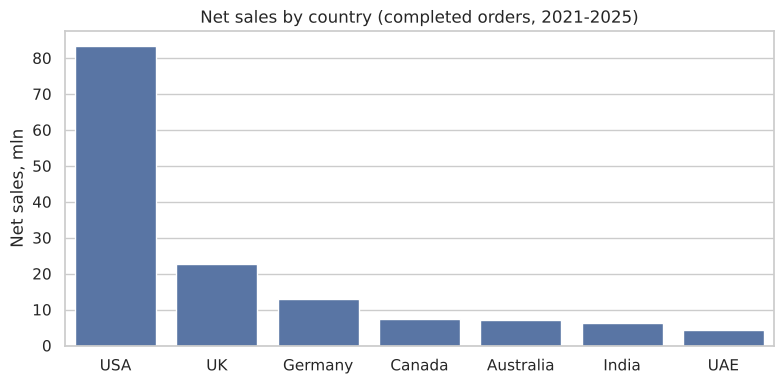

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=by_country.index.astype(str), y=by_country["net_sales"] / 1e6, color="#4C72B0", ax=ax)
ax.set(title="Net sales by country (completed orders, 2021-2025)", xlabel="", ylabel="Net sales, mln")
plt.tight_layout()
plt.show()

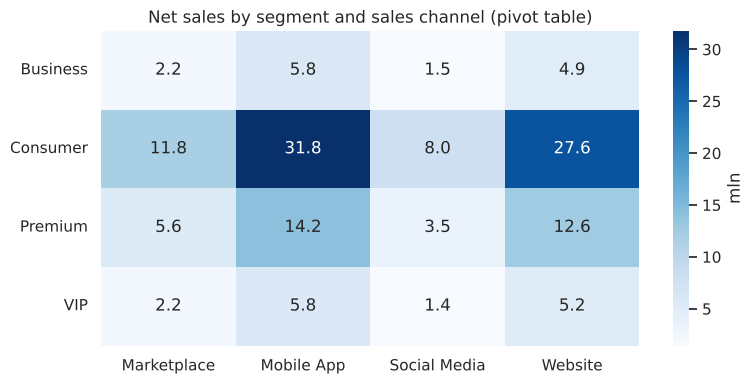

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "mln"}, ax=ax)
ax.set(title="Net sales by segment and sales channel (pivot table)", xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

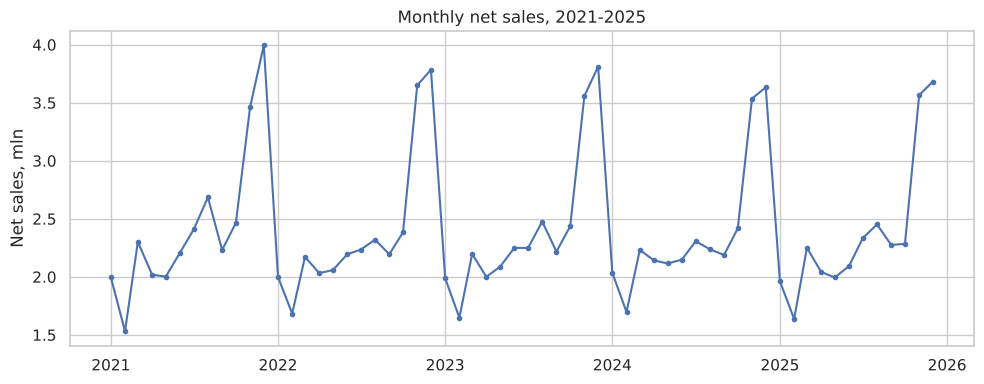

In [22]:
monthly = df.groupby("order_month")["net_sales"].sum() / 1e6
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pd.to_datetime(monthly.index), monthly.values, marker="o", markersize=3)
ax.set(title="Monthly net sales, 2021-2025", xlabel="", ylabel="Net sales, mln")
plt.tight_layout()
plt.show()

In [23]:
season = df.assign(m=df["order_date"].dt.month).groupby("m")["net_sales"].sum() / df["order_year"].nunique() / 1e6
print("Average net sales per calendar month, mln:")
print(season.round(2).to_string())
print(f"\nNov-Dec share of yearly sales: {season.loc[[11, 12]].sum() / season.sum():.1%}")
print("Yearly totals, mln:", (df.groupby("order_year")["net_sales"].sum() / 1e6).round(2).to_dict())

Average net sales per calendar month, mln:
m
1     2.00
2     1.64
3     2.23
4     2.05
5     2.05
6     2.18
7     2.31
8     2.43
9     2.22
10    2.40
11    3.55
12    3.78

Nov-Dec share of yearly sales: 25.4%
Yearly totals, mln: {2021: 29.3, 2022: 28.71, 2023: 28.92, 2024: 28.69, 2025: 28.57}


Sales are stable from year to year (28.6–29.3 mln) but strongly seasonal: November and December average 3.5–3.8 mln each versus about 2.0–2.4 mln in other months, and together give about 25% of yearly sales (two months would be 17% if sales were even). February is the weakest month.

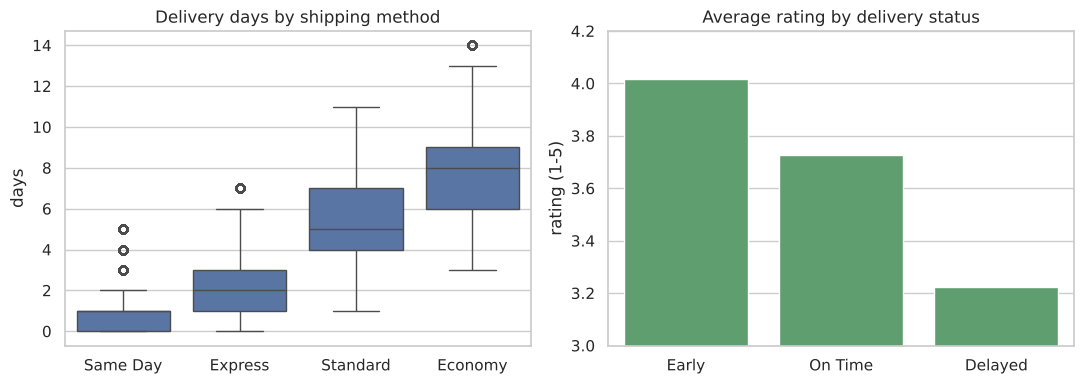

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = ["Same Day", "Express", "Standard", "Economy"]
sns.boxplot(data=df, x="shipping_method", y="delivery_days", order=order, ax=axes[0])
axes[0].set(title="Delivery days by shipping method", xlabel="", ylabel="days")
sns.barplot(data=q_join2, x="delivery_status", y="avg_rating", color="#55A868", ax=axes[1])
axes[1].set(title="Average rating by delivery status", xlabel="", ylabel="rating (1-5)", ylim=(3, 4.2))
plt.tight_layout()
plt.show()

## Task 4. ETL pipeline

In [25]:
SOURCE = CSV_PATH
TARGET = "orders_etl"

KEEP = ["order_id", "order_date", "order_time", "order_status", "sales_channel", "customer_id",
        "customer_segment", "customer_country", "payment_method", "shipping_method",
        "delivery_days", "estimated_delivery_days", "delivery_status", "customer_rating",
        "marketing_channel", "campaign_name", "coupon_code", "quantity", "gross_sales",
        "discount_amount", "net_sales", "product_cost", "profit"]

def extract(path):
    df = pd.read_csv(path)
    print(f"[extract]   {path}: {df.shape[0]} rows, {df.shape[1]} columns")
    return df

def transform(df):
    df = df[KEEP].copy()                                         # select required columns (drops order_date_parsed etc.)
    df = df.rename(columns={"customer_segment": "segment", "customer_country": "country",
                            "order_status": "status", "customer_rating": "rating"})
    df = df.drop_duplicates(subset="order_id")                   # one row per order
    # data types
    df["order_datetime"] = pd.to_datetime(df["order_date"] + " " + df["order_time"])
    df = df.drop(columns=["order_date", "order_time"])
    # missing values
    df["campaign_name"] = df["campaign_name"].fillna("No campaign")
    df["has_coupon"] = df["coupon_code"].notna().astype(int)
    df = df.drop(columns="coupon_code")
    # filter rows: pending orders are not finished yet
    df = df[df["status"] != "Pending"]
    # new columns
    df["year_month"] = df["order_datetime"].dt.strftime("%Y-%m")
    df["delivery_delay"] = df["delivery_days"] - df["estimated_delivery_days"]
    df["discount_pct"] = (100 * df["discount_amount"] / df["gross_sales"]).round(2)
    df["is_completed"] = (df["status"] == "Completed").astype(int)
    df = df.reset_index(drop=True)
    print(f"[transform] {df.shape[0]} rows, {df.shape[1]} columns")
    return df

def load(df, engine, table):
    with engine.begin() as conn:
        df.to_sql(table, conn, if_exists="replace", index=False)
    print(f"[load]      table '{table}' written")

def verify(engine, table, n=5):
    with engine.connect() as conn:
        count = conn.execute(text(f"SELECT COUNT(*) FROM {table}")).scalar()
        sample = pd.read_sql(text(f"SELECT * FROM {table} LIMIT {n}"), conn)
    print(f"[verify]    '{table}' contains {count} rows")
    return sample

def run_etl():
    raw = extract(SOURCE)
    clean = transform(raw)
    load(clean, engine, TARGET)
    return raw, clean, verify(engine, TARGET)

raw_df, clean_df, sample = run_etl()
sample

[extract]   ecommerce_clean.csv: 138116 rows, 47 columns
[transform] 131419 rows, 26 columns
[load]      table 'orders_etl' written
[verify]    'orders_etl' contains 131419 rows


,order_id,status,sales_channel,customer_id,segment,country,payment_method,shipping_method,delivery_days,estimated_delivery_days,delivery_status,rating,marketing_channel,campaign_name,quantity,gross_sales,discount_amount,net_sales,product_cost,profit,order_datetime,has_coupon,year_month,delivery_delay,discount_pct,is_completed
0,ORD-301242,Completed,Mobile App,CUST-003102,Consumer,USA,Digital Wallet,Standard,3.0,3.0,On Time,3.5,Direct,Default_Campaign,5,1350.19,477.89,945.40,588.33,345.04,2023-11-06 16:37:47,0,2023-11,0.0,35.39,1
1,ORD-773460,Completed,Website,CUST-003124,Premium,Germany,Debit Card,Economy,10.0,10.0,On Time,3.6,Direct,Default_Campaign,8,3144.64,1456.06,2018.41,2031.88,-22.47,2025-12-24 01:22:36,0,2025-12,0.0,46.30,1
2,ORD-449374,Completed,Mobile App,CUST-012496,Premium,USA,Cash on Delivery,Express,3.0,3.0,On Time,4.3,YouTube,No campaign,5,522.81,97.30,468.35,257.73,197.57,2021-07-05 14:24:21,0,2021-07,0.0,18.61,1
3,ORD-567636,Completed,Social Media,CUST-023928,Consumer,USA,Debit Card,Express,2.0,2.0,On Time,3.5,Email Marketing,No campaign,2,544.62,53.34,546.52,277.84,247.83,2023-01-21 07:20:26,0,2023-01,0.0,9.79,1
4,ORD-820028,Completed,Social Media,CUST-012730,Consumer,India,Digital Wallet,Standard,6.0,5.0,Delayed,3.0,Direct,No campaign,6,2474.52,133.63,2785.27,1231.88,1530.36,2022-05-13 09:46:21,0,2022-05,1.0,5.40,1


## Task 5. Data check
Read the loaded table back and compare it with the source CSV: number of records, missing values, duplicates and data types.

In [26]:
with engine.connect() as conn:
    db_df = pd.read_sql(text(f"SELECT * FROM {TARGET}"), conn)

summary = pd.DataFrame({
    "source CSV":     [len(raw_df), raw_df["order_id"].nunique(), int(raw_df.isna().sum().sum()),
                       int(raw_df.duplicated().sum()), raw_df.shape[1]],
    "database table": [len(db_df), db_df["order_id"].nunique(), int(db_df.isna().sum().sum()),
                       int(db_df.duplicated().sum()), db_df.shape[1]],
}, index=["records", "unique order_id", "missing values", "duplicate rows", "columns"])
summary

,source CSV,database table
records,138116,131419
unique order_id,138116,131419
missing values,573828,71440
duplicate rows,0,0
columns,47,26


In [27]:
common = ["delivery_days", "estimated_delivery_days", "customer_rating", "campaign_name", "coupon_code",
          "return_reason", "review_sentiment", "customer_review"]
na_cmp = pd.DataFrame({"source CSV": raw_df[common].isna().sum()})
na_cmp["database table"] = (db_df.rename(columns={"rating": "customer_rating"})
                            .reindex(columns=common).isna().sum())
na_cmp.loc[["coupon_code", "return_reason", "review_sentiment", "customer_review"], "database table"] = np.nan
na_cmp["comment"] = ["not delivered (cancelled/returned)", "not delivered (cancelled/returned)",
                     "no rating for non-completed orders", "filled with 'No campaign'",
                     "replaced by has_coupon flag", "column not loaded", "column not loaded", "column not loaded"]
na_cmp

,source CSV,database table,comment
delivery_days,24557,17860.0,not delivered (cancelled/returned)
estimated_delivery_days,24557,17860.0,not delivered (cancelled/returned)
customer_rating,24557,17860.0,no rating for non-completed orders
campaign_name,83233,0.0,filled with 'No campaign'
coupon_code,110502,NaN,replaced by has_coupon flag
return_reason,128654,NaN,column not loaded
review_sentiment,24557,NaN,column not loaded
customer_review,24557,NaN,column not loaded


In [28]:
print("Missing values left in the database table, by status:")
print(db_df.groupby("status")[["delivery_days", "rating"]].apply(lambda g: g.isna().sum()))

Missing values left in the database table, by status:
           delivery_days  rating
status                          
Cancelled           8398    8398
Completed              0       0
Returned            9462    9462


In [29]:
renamed = raw_df.rename(columns={"customer_segment": "segment", "customer_country": "country",
                                 "order_status": "status", "customer_rating": "rating"})
dtype_cmp = pd.concat({"source CSV": renamed.dtypes.astype(str),
                       "processed DataFrame": clean_df.dtypes.astype(str),
                       "database table": db_df.dtypes.astype(str)}, axis=1)
dtype_cmp = dtype_cmp.loc[clean_df.columns.union(["order_date", "order_time", "coupon_code"], sort=False)].fillna("—")
dtype_cmp

,source CSV,processed DataFrame,database table
order_id,str,str,str
status,str,str,str
sales_channel,str,str,str
customer_id,str,str,str
segment,str,str,str
country,str,str,str
payment_method,str,str,str
shipping_method,str,str,str
delivery_days,float64,float64,float64
estimated_delivery_days,float64,float64,float64


In [ ]:
n_pending = int((raw_df["order_status"] == "Pending").sum())
flow = pd.Series({"source rows": len(raw_df),
                  "duplicate order_id removed": -int(raw_df["order_id"].duplicated().sum()),
                  "pending orders removed": -n_pending,
                  "rows in database": len(db_df)})
print(flow.to_string())
assert flow.iloc[:-1].sum() == len(db_df)

check = run_query("""
    SELECT COUNT(*) AS n, ROUND(SUM(net_sales), 2) AS net_sales, ROUND(SUM(profit), 2) AS profit
    FROM orders WHERE order_status <> 'Pending'
""").iloc[0]
recon = pd.DataFrame({"orders table (SQL)": [check["n"], check["net_sales"], check["profit"]],
                      "orders_etl table": [len(db_df), round(db_df["net_sales"].sum(), 2), round(db_df["profit"].sum(), 2)]},
                     index=["records", "net_sales", "profit"])
recon["difference"] = recon.iloc[:, 1] - recon.iloc[:, 0]
recon.map(lambda v: f"{v:,.2f}")

source rows                   138116
duplicate order_id removed         0
pending orders removed         -6697
rows in database              131419


,orders table (SQL),orders_etl table,difference
records,"131,419.00","131,419.00",0.00
net_sales,"168,724,993.06","168,724,993.06",0.00
profit,"72,658,214.79","72,658,214.79",0.00


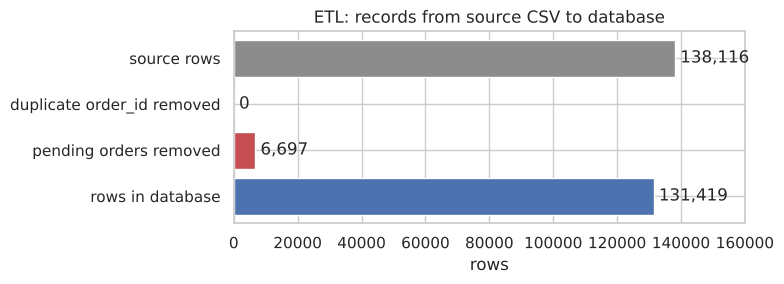

In [31]:
fig, ax = plt.subplots(figsize=(8, 3))
labels = ["rows in database", "pending orders removed", "duplicate order_id removed", "source rows"]
vals = [len(db_df), n_pending, 0, len(raw_df)]
ax.barh(labels, vals, color=["#4C72B0", "#C44E52", "#C44E52", "#8C8C8C"])
for i, v in enumerate(vals):
    ax.text(v, i, f" {v:,}", va="center")
ax.set(title="ETL: records from source CSV to database", xlabel="rows", xlim=(0, 160000))
plt.tight_layout()
plt.show()

## Five findings about the ETL results

1. **Record count is fully explained.** 138,116 rows in the source CSV → 131,419 rows in `orders_etl`. The only removed records are the 6,697 pending orders; there were no duplicate rows and no duplicate `order_id` either in the source or in the database (the `assert` confirms the balance).
2. **Missing values: 573,828 → 71,440.** Most of the reduction comes from not loading text and mostly-empty columns (`customer_review`, `return_reason`, `coupon_code`; 47 → 26 columns). `campaign_name` was filled with `"No campaign"` (83,233 → 0) and `coupon_code` was replaced by the `has_coupon` flag.
3. **The remaining missing values are structural, not errors.** All 17,860 empty `delivery_days`, `estimated_delivery_days`, `rating` and `delivery_delay` values belong exactly to cancelled (8,398) and returned (9,462) orders, which have no delivery or review. They were left empty on purpose: filling them with a median would invent delivery times for orders that were never delivered.
4. **Data types change between pandas and SQLite.** `order_date` + `order_time` (text) became one `datetime64` column in the processed DataFrame, but SQLite returns it as `str`, so it must be re-parsed (`parse_dates=["order_datetime"]`) when reading. Flags (`has_coupon`, `is_completed`) are stored as 0/1 integers because SQLite has no boolean type, and `delivery_days` stays `float64` because of the structural NaN.
5. **Financial totals reconcile exactly.** Net sales (168.72 mln) and profit (72.66 mln) in `orders_etl` are identical to the SQL totals over the relational `orders` table for non-pending orders — difference 0.00, so the transformations did not distort any amount.
